# Model comparison and test of H0/H1

**RQ1:** How do logistic regression (LR), random forest (RF) and gradient boosting (GB) compare in identifying relevant competency–course pairs?

* **H0:** there is no difference in macro-F1 among LR, RF and GB.
* **H1:** at least one method differs in macro-F1.

Procedure: (1) all methods and two baselines on the primary split with exact McNemar tests; (2) the whole pipeline repeated on 30 grouped splits (seeds 1000–1029, TF-IDF refitted each time); (3) Friedman test with Kendall’s W, Wilcoxon signed-rank tests with Holm correction and bootstrap confidence intervals (Demšar-style comparison).

## 1. Data, preparation and models

In [1]:
# Paths: works in Google Colab (files in Google Drive) and on a local computer.
from pathlib import Path
import hashlib, json, re, time, warnings, platform, importlib.metadata
import numpy as np
import pandas as pd
warnings.filterwarnings('ignore')

try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = Path('/content/drive/MyDrive/Assignment3_TulegenovaK')  # folder with manual_records.csv
except ImportError:
    BASE = Path.cwd()  # local run: the notebook sits next to manual_records.csv

RESULT = BASE / 'results'
RESULT.mkdir(exist_ok=True)
SEED = 42

versions = {'python': platform.python_version(),
            **{p: importlib.metadata.version(p) for p in ['pandas', 'numpy', 'scipy', 'scikit-learn', 'matplotlib']}}
print(json.dumps(versions, indent=2))

# Integrity check: the CSV must be the same file that was verified in the source manifest.
manifest = json.loads((BASE / 'source_manifest.json').read_text(encoding='utf-8'))
assert hashlib.sha256((BASE / 'manual_records.csv').read_bytes()).hexdigest() == manifest['manual_csv_sha256']
raw = pd.read_csv(BASE / 'manual_records.csv')
print('Manual UniSkill records:', len(raw))

{
  "python": "3.9.6",
  "pandas": "2.3.3",
  "numpy": "2.0.2",
  "scipy": "1.13.1",
  "scikit-learn": "1.6.1",
  "matplotlib": "3.9.4"
}
Manual UniSkill records: 1098


In [2]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# 1) Cleaning (identical to the Logistic Regression notebook)
TEXT_COLS = ['skill_label', 'skill_description', 'matched_course_sentence', 'course_title']
df = raw.copy()
for c in TEXT_COLS:
    df[c] = df[c].fillna('').astype(str).str.replace(r'\s+', ' ', regex=True).str.strip()
df = df.drop_duplicates(TEXT_COLS).reset_index(drop=True)
df['record_id'] = [f'R{i:04d}' for i in range(len(df))]
df['skill_text'] = df.skill_label + ' ' + df.skill_description
y = df.eval_all.astype(int).to_numpy()

# 2) Connected groups: records that share a course title or a course sentence stay together
parent = list(range(len(df)))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i
for col in ['course_title', 'matched_course_sentence']:
    seen = {}
    for i, t in enumerate(df[col]):
        k = t.casefold()
        if k in seen:
            parent[find(seen[k])] = find(i)
        else:
            seen[k] = i
df['group'] = [find(i) for i in range(len(df))]

def grouped_split(seed):
    """20% of groups -> test, 25% of the remaining groups -> validation."""
    dev, test = next(GroupShuffleSplit(1, test_size=0.2, random_state=seed).split(df, groups=df.group))
    a, b = next(GroupShuffleSplit(1, test_size=0.25, random_state=seed).split(df.iloc[dev], groups=df.group.iloc[dev]))
    return dev[a], dev[b], test

# 3) Five lexical features (TF-IDF is fitted on training text only)
def jaccard(a, b):
    a, b = set(re.findall(r'\b\w+\b', a.casefold())), set(re.findall(r'\b\w+\b', b.casefold()))
    return len(a & b) / len(a | b) if a | b else 0.0
JAC_S = np.array([jaccard(a, b) for a, b in zip(df.matched_course_sentence, df.skill_label)])
JAC_T = np.array([jaccard(a, b) for a, b in zip(df.course_title, df.skill_label)])
FEATURES = ['cos_sentence', 'cos_title', 'cos_min', 'jaccard_sentence', 'jaccard_title']

def lexical_features(train_idx):
    vec = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), max_features=20000, norm='l2')
    t = df.iloc[train_idx]
    vec.fit(pd.concat([t.course_title, t.matched_course_sentence, t.skill_text]).tolist())
    sk, ti, se = (vec.transform(df[c]) for c in ['skill_text', 'course_title', 'matched_course_sentence'])
    cs = np.asarray(se.multiply(sk).sum(1)).ravel()
    ct = np.asarray(ti.multiply(sk).sum(1)).ravel()
    return np.column_stack([cs, ct, np.minimum(cs, ct), JAC_S, JAC_T])

# 4) Threshold choice on validation data and evaluation helpers
THRESHOLDS = np.linspace(0.05, 0.95, 19)
def pick_threshold(y_val, p_val, grid=THRESHOLDS):
    scores = [(f1_score(y_val, p_val >= t, average='macro', zero_division=0), t) for t in grid]
    best = max(s for s, _ in scores)
    return min((t for s, t in scores if s == best), key=lambda t: (abs(t - 0.5), t))

def evaluate(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    return dict(accuracy=accuracy_score(y_true, y_pred),
                precision=precision_score(y_true, y_pred, zero_division=0),
                recall=recall_score(y_true, y_pred, zero_division=0),
                f1_match=f1_score(y_true, y_pred, zero_division=0),
                macro_f1=f1_score(y_true, y_pred, average='macro', zero_division=0),
                TN=int(cm[0, 0]), FP=int(cm[0, 1]), FN=int(cm[1, 0]), TP=int(cm[1, 1]))

train_idx, val_idx, test_idx = grouped_split(SEED)
X = lexical_features(train_idx)
print('Clean records:', len(df), '| classes:', dict(zip(*np.unique(y, return_counts=True))))
print('Connected groups:', df.group.nunique(), '| largest group:', df.groupby('group').size().max())
print('Split sizes (train / validation / test):', len(train_idx), len(val_idx), len(test_idx))
assert (len(train_idx), len(val_idx), len(test_idx)) == (649, 231, 216), 'Split differs from the LR notebook'
for a, b in [(train_idx, val_idx), (train_idx, test_idx), (val_idx, test_idx)]:
    assert not set(df.group.iloc[a]) & set(df.group.iloc[b])
print('Feature matrix:', X.shape)

Clean records: 1096 | classes: {np.int64(0): np.int64(700), np.int64(1): np.int64(396)}
Connected groups: 544 | largest group: 21
Split sizes (train / validation / test): 649 231 216
Feature matrix: (1096, 5)


In [3]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

def make_models(seed):
    """Hyperparameters are fixed in advance and identical for every split."""
    return {
        'LR': make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=1000, class_weight='balanced', random_state=seed)),
        'RF': RandomForestClassifier(n_estimators=500, min_samples_leaf=5, class_weight='balanced', random_state=seed, n_jobs=-1),
        'GB': GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=seed),
    }
NAMES = {'LR': 'Logistic regression', 'RF': 'Random forest', 'GB': 'Gradient boosting',
         'Cosine': 'Cosine baseline', 'Majority': 'Majority baseline'}
from scipy import stats

def run(seed):
    """Full pipeline for one grouped split: features, 3 classifiers, 2 baselines."""
    tr, va, te = grouped_split(seed)
    Xs = lexical_features(tr)
    res, preds, probs, thr = {}, {}, {}, {}
    for name, m in make_models(seed).items():
        m.fit(Xs[tr], y[tr])
        p = m.predict_proba(Xs)[:, 1]
        t = pick_threshold(y[va], p[va])
        preds[name], probs[name], thr[name] = (p[te] >= t).astype(int), p[te], t
        res[name] = dict(evaluate(y[te], preds[name]), threshold=t)
    majority = int(np.bincount(y[tr]).argmax())
    preds['Majority'] = np.full(len(te), majority)
    res['Majority'] = dict(evaluate(y[te], preds['Majority']), threshold=np.nan)
    c = Xs[:, 2]                                   # minimum cosine similarity
    grid = np.unique(np.quantile(c[tr], np.linspace(0, 1, 101)))
    t = pick_threshold(y[va], c[va], grid)
    preds['Cosine'] = (c[te] >= t).astype(int)
    res['Cosine'] = dict(evaluate(y[te], preds['Cosine']), threshold=t)
    return tr, va, te, Xs, res, preds, probs

## 2. Primary split (seed 42, 216 test pairs)

In [4]:
tr, va, te, Xp, res, preds, probs = run(SEED)
primary = pd.DataFrame(res).T[['accuracy', 'precision', 'recall', 'f1_match', 'macro_f1', 'TN', 'FP', 'FN', 'TP', 'threshold']]
print(primary.round(4).to_string())
assert abs(res['LR']['macro_f1'] - 0.693764) < 1e-4, 'LR must reproduce LogisticRegression.ipynb'
primary.to_csv(RESULT / 'primary_metrics.csv')

# Predictions with features, used by the qualitative notebook
tp = df.iloc[te].copy()
for n, p in preds.items(): tp['pred_' + n] = p
for n, p in probs.items(): tp['prob_' + n] = p
for j, f in enumerate(['cos_sent', 'cos_title', 'cos_min', 'jac_sent', 'jac_title']): tp[f] = Xp[te, j]
tp.to_csv(RESULT / 'primary_test_predictions.csv', index=False)

def mcnemar(a, b):
    ca, cb = preds[a] == y[te], preds[b] == y[te]
    n01, n10 = int((ca & ~cb).sum()), int((~ca & cb).sum())
    p = stats.binomtest(min(n01, n10), n01 + n10, 0.5).pvalue if n01 + n10 else 1.0
    return dict(pair=f'{a}-{b}', only_first_correct=n01, only_second_correct=n10, exact_p=p)
mcn = pd.DataFrame([mcnemar(a, b) for a, b in [('LR', 'RF'), ('LR', 'GB'), ('RF', 'GB')]])
print('\nExact McNemar tests on the primary split:')
print(mcn.round(4).to_string(index=False))

          accuracy  precision  recall  f1_match  macro_f1     TN    FP    FN    TP  threshold
LR          0.7269     0.7049  0.5119    0.5931    0.6938  114.0  18.0  41.0  43.0     0.5500
RF          0.7176     0.6095  0.7619    0.6772    0.7131   91.0  41.0  20.0  64.0     0.5000
GB          0.6944     0.5789  0.7857    0.6667    0.6923   84.0  48.0  18.0  66.0     0.3500
Majority    0.6111     0.0000  0.0000    0.0000    0.3793  132.0   0.0  84.0   0.0        NaN
Cosine      0.7176     0.7170  0.4524    0.5547    0.6740  117.0  15.0  46.0  38.0     0.0293

Exact McNemar tests on the primary split:
 pair  only_first_correct  only_second_correct  exact_p
LR-RF                  27                   25   0.8899
LR-GB                  33                   26   0.4350
RF-GB                  12                    7   0.3593


## 3. Thirty repeated grouped splits

In [5]:
rows = []
for s in range(30):
    _, _, _, _, r, _, _ = run(1000 + s)
    for n, v in r.items():
        rows.append(dict(seed=1000 + s, method=n, **v))
R = pd.DataFrame(rows)
R.to_csv(RESULT / 'repeated_metrics.csv', index=False)
W = R.pivot(index='seed', columns='method', values='macro_f1')
summary = R.groupby('method')[['macro_f1', 'accuracy', 'precision', 'recall']].agg(['mean', 'std'])
print(summary.loc[['LR', 'RF', 'GB', 'Cosine', 'Majority']].round(3).to_string())
best = W[['LR', 'RF', 'GB']].idxmax(axis=1).value_counts()
print('\nBest classifier per split:', best.to_dict())

         macro_f1        accuracy        precision        recall       
             mean    std     mean    std      mean    std   mean    std
method                                                                 
LR          0.678  0.042    0.707  0.051     0.583  0.069  0.603  0.069
RF          0.655  0.035    0.680  0.044     0.540  0.062  0.621  0.079
GB          0.637  0.045    0.670  0.053     0.538  0.081  0.551  0.107
Cosine      0.628  0.040    0.676  0.060     0.563  0.093  0.478  0.101
Majority    0.393  0.020    0.649  0.055     0.000  0.000  0.000  0.000

Best classifier per split: {'LR': 21, 'RF': 7, 'GB': 2}


## 4. Hypothesis test of H0 (Friedman) and pairwise comparisons

In [6]:
fr = stats.friedmanchisquare(W.LR, W.RF, W.GB)
n, k = len(W), 3
kendall_w = fr.statistic / (n * (k - 1))
ranks = W[['LR', 'RF', 'GB']].rank(axis=1, ascending=False).mean()
print(f'Friedman chi2({k-1}) = {fr.statistic:.2f}, p = {fr.pvalue:.2e}, Kendall W = {kendall_w:.2f}')
print('Mean ranks (1 = best):', ranks.round(2).to_dict())
print('Decision:', 'reject H0 -> H1 supported' if fr.pvalue < 0.05 else 'H0 not rejected')

pw = []
rng = np.random.default_rng(0)
for a, b in [('LR', 'RF'), ('LR', 'GB'), ('RF', 'GB')]:
    d = (W[a] - W[b]).values
    boot = [rng.choice(d, len(d)).mean() for _ in range(5000)]
    w = stats.wilcoxon(W[a], W[b])
    pw.append(dict(pair=f'{a}-{b}', mean_diff=d.mean(), ci_low=np.percentile(boot, 2.5), ci_high=np.percentile(boot, 97.5),
                   W=w.statistic, p=w.pvalue, wins_first=int((d > 0).sum()), wins_second=int((d < 0).sum())))
pw = pd.DataFrame(pw).sort_values('p').reset_index(drop=True)
adj, running = [], 0                    # Holm step-down correction
for i, p in enumerate(pw.p):
    running = max(running, min(1, (len(pw) - i) * p)); adj.append(running)
pw['p_holm'] = adj
print(pw.round(4).to_string(index=False))

print('\nClassifiers vs the cosine baseline (Wilcoxon):')
vs_base = {m: stats.wilcoxon(W[m], W['Cosine']).pvalue for m in ['LR', 'RF', 'GB']}
print({m: round(p, 4) for m, p in vs_base.items()})

json.dump(dict(friedman_chi2=fr.statistic, friedman_p=fr.pvalue, kendall_w=kendall_w, mean_ranks=ranks.to_dict(),
               mcnemar=mcn.to_dict('records'), pairwise=pw.to_dict('records'), vs_cosine=vs_base,
               mean_macro_f1=W.mean().to_dict(), sd_macro_f1=W.std().to_dict(), versions=versions),
          open(RESULT / 'stats.json', 'w'), indent=2, default=float)

Friedman chi2(2) = 25.40, p = 3.05e-06, Kendall W = 0.42
Mean ranks (1 = best): {'LR': 1.37, 'RF': 1.97, 'GB': 2.67}
Decision: reject H0 -> H1 supported
 pair  mean_diff  ci_low  ci_high    W      p  wins_first  wins_second  p_holm
LR-GB     0.0406  0.0284   0.0521 23.0 0.0000          26            4  0.0000
LR-RF     0.0228  0.0123   0.0342 63.0 0.0002          23            7  0.0005
RF-GB     0.0178  0.0078   0.0264 69.0 0.0004          24            6  0.0005

Classifiers vs the cosine baseline (Wilcoxon):
{'LR': np.float64(0.0), 'RF': np.float64(0.0002), 'GB': np.float64(0.2367)}


## 5. Figure: macro-F1 over 30 splits

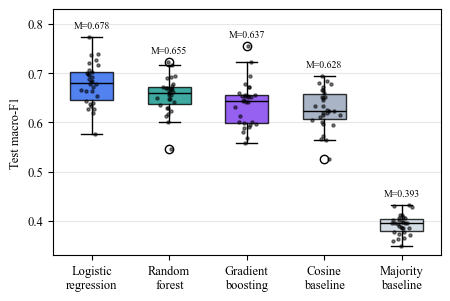

In [7]:
import matplotlib.pyplot as plt
plt.rcParams.update({'font.family': 'serif', 'font.serif': ['Times New Roman', 'Times', 'DejaVu Serif'], 'font.size': 9})
order = ['LR', 'RF', 'GB', 'Cosine', 'Majority']
labels = {'LR': 'Logistic\nregression', 'RF': 'Random\nforest', 'GB': 'Gradient\nboosting',
          'Cosine': 'Cosine\nbaseline', 'Majority': 'Majority\nbaseline'}
fig, ax = plt.subplots(figsize=(5, 3.2))
data = [W[m] for m in order]
bp = ax.boxplot(data, patch_artist=True, widths=0.55, medianprops=dict(color='black'))
for p, c in zip(bp['boxes'], ['#2563eb', '#0d9488', '#7c3aed', '#94a3b8', '#cbd5e1']):
    p.set_facecolor(c); p.set_alpha(0.8)
for i, v in enumerate(data):
    ax.scatter(np.random.default_rng(i).normal(i + 1, 0.06, len(v)), v, s=5, color='black', alpha=0.5, zorder=3)
    ax.text(i + 1, v.max() + 0.018, f'M={v.mean():.3f}', ha='center', fontsize=7)
ax.set_xticks(range(1, 6), [labels[m] for m in order]); ax.set_ylabel('Test macro-F1')
ax.grid(axis='y', alpha=0.3); ax.set_axisbelow(True); ax.set_ylim(0.33, 0.83)
fig.savefig(RESULT / 'fig_macro_f1_boxplot.png', dpi=300, bbox_inches='tight')
plt.show()

## 6. Interpretation

On the primary split the three classifiers are close and the McNemar tests are not significant, so one split cannot rank them. Over 30 grouped splits the Friedman test rejects H0, and all pairwise differences remain significant after Holm correction: LR > RF > GB. LR and RF beat the cosine baseline; GB does not.